# CTC Extension of the Original AToum Mean-Field Model

This notebook **extends the original population-rate model** in `model_class.py`; it does not replace it with the simplified GNW mean-field prototype. The original two excitatory populations, inhibitory population, synaptic states, attention variables, hierarchy, and FLN-derived long-range weights remain in use.

The added mechanism is deliberately narrow: a Kuramoto-style phase population evolves over the anatomical FLN graph, and its phase differences modulate only long-range excitatory-to-excitatory inputs. Local dynamics and long-range excitation to inhibition are unchanged. The original `Model` remains the no-CTC control.

The preferred phase offset and all oscillator parameters are provisional. This notebook is a mechanism prototype, not a calibrated biological CTC model.

## Step 1: Load the original model and the CTC extension

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "model_class.py").is_file() and (p / "data").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from the project folder or one of its subfolders.")

# The original model uses relative data and cache paths, so run from the repository root.
os.chdir(project_root)
for module_dir in (project_root, project_root / "simulations", project_root / "toolboxes"):
    if str(module_dir) not in sys.path:
        sys.path.insert(0, str(module_dir))

from brian2 import Hz, ms, pA, second
from ctc_model import CTCModel
from model_class import Model
from simulations.simulation import Simulation
from template_kwargs import template_kwargs
from toolboxes.model_toolbox import get_full_kwargs
from gnw_metrics import compute_ignition_metrics, resolve_area_indices

print("Project root:", project_root)
print("Original rate model:", Model)
print("CTC extension:", CTCModel)

Project root: D:\Project\pythonProject\atoum-master
Original rate model: <class 'model_class.Model'>
CTC extension: <class 'ctc_model.CTCModel'>


## Step 2: Prepare the original 40-area network

In [2]:
# Use the original model's 40-area anatomy and resting-state initialization.
# The cache avoids repeating the longer resting-state calibration on later runs.
(project_root / "data" / "full_kwargs").mkdir(parents=True, exist_ok=True)
network_params = dict(template_kwargs)
network_params.update({
    "run_t": 500 * ms,
    "stim_on": 50 * ms,
    "stim_off": 150 * ms,
    "active_area": [b"V4"],
    "sigma_e": 0 * pA,
    "sigma_i": 0 * pA,
    # Keep attention neutral so this first experiment isolates phase gating.
    "attention_baseline_gain": 1.0,
    "attention_task_gain": 0.0,
    "attention_reentry_gain": 0.0,
    "attention_reentry_current": 0 * pA,
})
network_params = get_full_kwargs(network_params)
connectivity_path = project_root / "data" / network_params["connectivity_file"]
with open(connectivity_path, "rb") as connectivity_file:
    anatomy = np.load(connectivity_file, allow_pickle=True, encoding="bytes")
area_names = [
    x.decode("utf-8") if isinstance(x, bytes) else str(x)
    for x in anatomy[b"area_list"]
]
workspace_areas = ["F1", "F2", "F3", "F4", "7a", "7b"]
workspace_indices = resolve_area_indices(area_names, workspace_areas)
v4_index = area_names.index("V4")
time_ms = np.asarray(network_params["run_t"] / ms * np.linspace(
    0, 1, int(network_params["run_t"] / network_params["dt"]) + 1
), dtype=float)
stimulus_on_ms = float(network_params["stim_on"] / ms)
stimulus_off_ms = float(network_params["stim_off"] / ms)

print("Areas:", len(area_names))
print("V4 index:", v4_index)
print("Workspace:", workspace_areas)
print("dt:", float(network_params["dt"] / ms), "ms")
print("Stimulus:", stimulus_on_ms, "to", stimulus_off_ms, "ms")

Areas: 40
V4 index: 2
Workspace: ['F1', 'F2', 'F3', 'F4', '7a', '7b']
dt: 0.5 ms
Stimulus: 50.0 to 150.0 ms


## Step 3: Define a runner that uses the original Simulation interface

In [3]:
recorders = {
    "r1_hz": {"function": lambda m: np.asarray(m.get_r(1) / Hz), "args": {}, "type": "at_the_end"},
    "r2_hz": {"function": lambda m: np.asarray(m.get_r(2) / Hz), "args": {}, "type": "at_the_end"},
    "ri_hz": {"function": lambda m: np.asarray(m.get_ri() / Hz), "args": {}, "type": "at_the_end"},
}


def run_original_condition(
    *,
    use_ctc=False,
    seed=1,
    phase_coupling_rad_s=15.0,
    phase_gate_depth=0.5,
    phase_mean_hz=40.0,
    phase_frequency_spread_hz=1.0,
    phase_diffusion_rad_sqrt_s=0.0,
    phase_preferred_offset_rad=0.0,
):
    """Run one trial on the original Model, optionally with phase-gated FLN input."""
    np.random.seed(seed)  # pair the original model's background noise by seed
    params = dict(network_params)
    if use_ctc:
        model = CTCModel(
            talky=False,
            network_params=params,
            phase_mean_hz=phase_mean_hz,
            phase_frequency_spread_hz=phase_frequency_spread_hz,
            phase_coupling_rad_s=phase_coupling_rad_s,
            phase_diffusion_rad_sqrt_s=phase_diffusion_rad_sqrt_s,
            phase_gate_depth=phase_gate_depth,
            phase_preferred_offset_rad=phase_preferred_offset_rad,
            phase_seed=10_000 + seed,
        )
        functions = dict(recorders)
        functions["phase_rad"] = {
            "function": lambda m: m.get_phase().copy(), "args": {}, "type": "at_the_end"
        }
        functions["phase_gate"] = {
            "function": lambda m: m.get_phase_gate().copy(), "args": {}, "type": "at_the_end"
        }
    else:
        model = Model(talky=False, network_params=params)
        functions = recorders

    simulation = Simulation(model, functions, talky=False)
    simulation.run(simulation_steps=1)
    return {
        "time_ms": np.asarray(model.t_plot / ms, dtype=float),
        "r1_hz": simulation.data["r1_hz"],
        "r2_hz": simulation.data["r2_hz"],
        "ri_hz": simulation.data["ri_hz"],
        "phase_rad": simulation.data.get("phase_rad"),
        "phase_gate": simulation.data.get("phase_gate"),
        "model": model,
    }


def excitatory_area_rates(result):
    """Mean the original model's two excitatory populations within each area."""
    return 0.5 * (result["r1_hz"] + result["r2_hz"])

print("Runner ready; the spiking model is not used in this notebook.")

Runner ready; the spiking model is not used in this notebook.


## Step 4: Check the no-CTC control reproduces the original model

In [4]:
baseline = run_original_condition(use_ctc=False, seed=1)
phase_only_control = run_original_condition(
    use_ctc=True,
    seed=1,
    phase_coupling_rad_s=15.0,
    phase_gate_depth=0.0,
)

baseline_rates = excitatory_area_rates(baseline)
phase_only_rates = excitatory_area_rates(phase_only_control)
max_abs_rate_difference_hz = float(np.max(np.abs(baseline_rates - phase_only_rates)))
print("Maximum rate difference with CTC gate depth = 0:", max_abs_rate_difference_hz, "Hz")
assert np.allclose(baseline_rates, phase_only_rates, rtol=0.0, atol=1e-8), (
    "Turning the CTC gate off should leave the original rates unchanged."
)
print("PASS: the CTC-off extension reproduces the original rate trajectories.")

Maximum rate difference with CTC gate depth = 0: 0.0 Hz
PASS: the CTC-off extension reproduces the original rate trajectories.


## Step 5: Define ignition and mean phase coherence readouts

In [5]:
ignition_threshold_hz = 20.0
ignition_duration_ms = 50.0


def phase_coherence_between_groups(phases_rad, group_a, group_b, time_mask):
    """Mean pairwise phase coherence across selected groups and a time window."""
    phases = np.asarray(phases_rad, dtype=float)[time_mask]
    a = np.asarray(group_a, dtype=int)
    b = np.asarray(group_b, dtype=int)
    if phases.size == 0 or len(a) == 0 or len(b) == 0:
        return float("nan")
    differences = phases[:, a, None] - phases[:, None, b]
    pairwise_coherence = np.abs(np.exp(1j * differences).mean(axis=0))
    return float(pairwise_coherence.mean())


def summarize_original_trial(result):
    times = result["time_ms"]
    rates = excitatory_area_rates(result)
    workspace_rate = rates[:, workspace_indices].mean(axis=1)
    ignition = compute_ignition_metrics(
        rates,
        times,
        workspace_indices,
        threshold_hz=ignition_threshold_hz,
        min_duration_ms=ignition_duration_ms,
        onset_ms=stimulus_on_ms,
    )
    late_window = (times >= stimulus_off_ms + 50.0) & (times <= times[-1])
    metrics = {
        "ignited": ignition["ignited"],
        "ignition_latency_ms": ignition["latency_ms"],
        "mean_workspace_rate_during_stim_hz": float(
            workspace_rate[(times >= stimulus_on_ms) & (times < stimulus_off_ms)].mean()
        ),
        "mean_workspace_rate_late_hz": float(workspace_rate[late_window].mean()),
        "max_workspace_area_rate_hz": float(rates[:, workspace_indices].max()),
    }
    if result["phase_rad"] is not None:
        stim_window = (times >= stimulus_on_ms) & (times < stimulus_off_ms)
        metrics["V4_to_workspace_MPC_during_stim"] = phase_coherence_between_groups(
            result["phase_rad"], [v4_index], workspace_indices, stim_window
        )
        metrics["V4_to_workspace_MPC_late"] = phase_coherence_between_groups(
            result["phase_rad"], [v4_index], workspace_indices, late_window
        )
    return metrics

print("Ignition threshold:", ignition_threshold_hz, "Hz for", ignition_duration_ms, "ms")

Ignition threshold: 20.0 Hz for 50.0 ms


## Step 6: Inspect one phase-gated run

Original model, CTC off: {'ignited': False, 'ignition_latency_ms': nan, 'mean_workspace_rate_during_stim_hz': 0.047611277619955886, 'mean_workspace_rate_late_hz': 0.024622186566506516, 'max_workspace_area_rate_hz': 0.6027509074605042}
Original model, CTC on: {'ignited': False, 'ignition_latency_ms': nan, 'mean_workspace_rate_during_stim_hz': 0.19496114122553793, 'mean_workspace_rate_late_hz': 7.310412749321251, 'max_workspace_area_rate_hz': 17.9361481894451, 'V4_to_workspace_MPC_during_stim': 0.9826898420963469, 'V4_to_workspace_MPC_late': 0.9969936620408203}


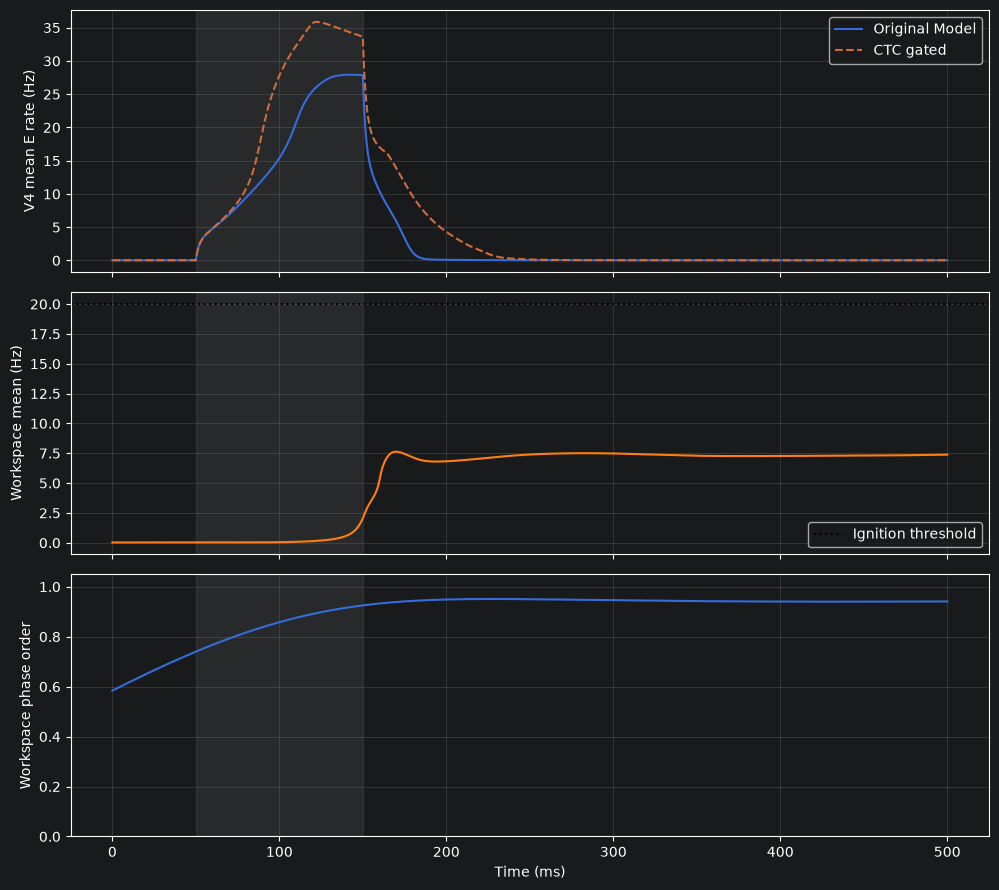

In [6]:
ctc_example = run_original_condition(
    use_ctc=True,
    seed=1,
    phase_coupling_rad_s=15.0,
    phase_gate_depth=0.5,
    phase_mean_hz=40.0,
    phase_frequency_spread_hz=1.0,
    phase_diffusion_rad_sqrt_s=0.0,
    phase_preferred_offset_rad=0.0,  # provisional; later scan this offset too
)
print("Original model, CTC off:", summarize_original_trial(baseline))
print("Original model, CTC on:", summarize_original_trial(ctc_example))

ctc_rates = excitatory_area_rates(ctc_example)
ctc_workspace = ctc_rates[:, workspace_indices].mean(axis=1)
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axes[0].plot(baseline["time_ms"], baseline_rates[:, v4_index], label="Original Model")
axes[0].plot(ctc_example["time_ms"], ctc_rates[:, v4_index], linestyle="--", label="CTC gated")
axes[0].set_ylabel("V4 mean E rate (Hz)")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(ctc_example["time_ms"], ctc_workspace, color="tab:orange")
axes[1].axhline(ignition_threshold_hz, color="black", linestyle=":", label="Ignition threshold")
axes[1].set_ylabel("Workspace mean (Hz)")
axes[1].legend()
axes[1].grid(alpha=0.25)
axes[2].plot(ctc_example["time_ms"], np.abs(np.exp(1j * ctc_example["phase_rad"][:, workspace_indices]).mean(axis=1)))
axes[2].set_ylabel("Workspace phase order")
axes[2].set_xlabel("Time (ms)")
axes[2].set_ylim(0, 1.05)
axes[2].grid(alpha=0.25)
for ax in axes:
    ax.axvspan(stimulus_on_ms, stimulus_off_ms, color="gray", alpha=0.15)
plt.tight_layout()
plt.show()

## Step 7: Small factorial scan of phase coupling and gate depth

In [7]:
# Pilot scan: 3 paired activity seeds, two gate depths, three phase-coupling levels.
# Gate depth 0 is the matched rate-only control for each phase-coupling setting.
phase_coupling_levels_rad_s = [0.0, 15.0, 30.0]
phase_gate_depth_levels = [0.0, 0.5]
ctc_scan_seeds = [1, 2, 3]
ctc_scan_rows = []

for coupling in tqdm(phase_coupling_levels_rad_s, desc="Phase coupling", unit="level"):
    for gate_depth in phase_gate_depth_levels:
        for seed in ctc_scan_seeds:
            result = run_original_condition(
                use_ctc=True,
                seed=seed,
                phase_coupling_rad_s=coupling,
                phase_gate_depth=gate_depth,
                phase_mean_hz=40.0,
                phase_frequency_spread_hz=1.0,
                phase_diffusion_rad_sqrt_s=0.0,
                phase_preferred_offset_rad=0.0,
            )
            metrics = summarize_original_trial(result)
            ctc_scan_rows.append({
                "phase_coupling_rad_s": coupling,
                "phase_gate_depth": gate_depth,
                "seed": seed,
                **metrics,
            })
            del result

ctc_scan = pd.DataFrame(ctc_scan_rows)
print(ctc_scan.round(3).to_string(index=False))

Phase coupling:   0%|          | 0/3 [00:00<?, ?level/s]

 phase_coupling_rad_s  phase_gate_depth  seed  ignited  ignition_latency_ms  mean_workspace_rate_during_stim_hz  mean_workspace_rate_late_hz  max_workspace_area_rate_hz  V4_to_workspace_MPC_during_stim  V4_to_workspace_MPC_late
                  0.0               0.0     1    False                  NaN                               0.048                        0.025                       0.603                            0.994                     0.948
                  0.0               0.0     2    False                  NaN                               0.048                        0.025                       0.603                            0.995                     0.953
                  0.0               0.0     3    False                  NaN                               0.048                        0.025                       0.603                            0.985                     0.875
                  0.0               0.5     1    False                  NaN             

## Step 8: Compare CTC gating with its matched phase-only control

 phase_coupling_rad_s  phase_gate_depth  ignition_probability  mean_ignition_latency_ms  mean_workspace_rate_late_hz  mean_V4_workspace_MPC_stim  mean_peak_workspace_area_rate_hz
                  0.0               0.0                   0.0                       NaN                        0.025                       0.991                             0.603
                  0.0               0.5                   0.0                       NaN                        0.037                       0.991                             0.552
                 15.0               0.0                   0.0                       NaN                        0.025                       0.974                             0.603
                 15.0               0.5                   0.0                       NaN                        4.817                       0.974                            11.934
                 30.0               0.0                   0.0                       NaN                  

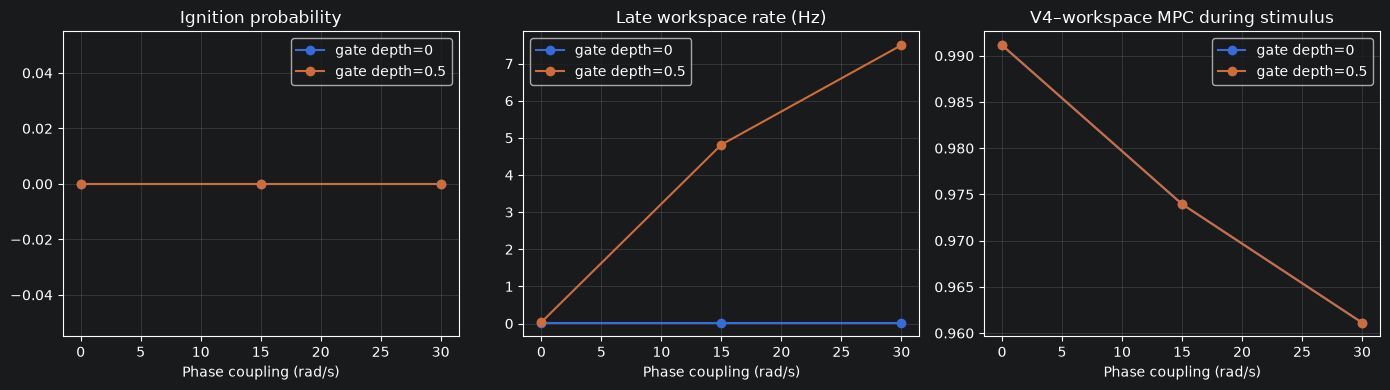

In [8]:
scan_summary = (
    ctc_scan.groupby(["phase_coupling_rad_s", "phase_gate_depth"], as_index=False)
    .agg(
        ignition_probability=("ignited", "mean"),
        mean_ignition_latency_ms=("ignition_latency_ms", "mean"),
        mean_workspace_rate_late_hz=("mean_workspace_rate_late_hz", "mean"),
        mean_V4_workspace_MPC_stim=("V4_to_workspace_MPC_during_stim", "mean"),
        mean_peak_workspace_area_rate_hz=("max_workspace_area_rate_hz", "mean"),
    )
)
print(scan_summary.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, title in [
    (axes[0], "ignition_probability", "Ignition probability"),
    (axes[1], "mean_workspace_rate_late_hz", "Late workspace rate (Hz)"),
    (axes[2], "mean_V4_workspace_MPC_stim", "V4–workspace MPC during stimulus"),
]:
    grid = scan_summary.pivot(index="phase_coupling_rad_s", columns="phase_gate_depth", values=metric)
    for gate_depth in phase_gate_depth_levels:
        ax.plot(grid.index, grid[gate_depth], marker="o", label=f"gate depth={gate_depth:g}")
    ax.set_xlabel("Phase coupling (rad/s)")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## How to interpret this prototype

- `phase_coupling_rad_s` controls how strongly phases interact through the FLN graph; `phase_gate_depth` controls how much phase difference changes long-range E-to-E transmission.
- `V4_to_workspace_MPC` is calculated from the oscillator phases explicitly present in the model; it does not use a Hilbert transform of firing-rate traces.
- The `phase_gate_depth=0` rows are the rate-only control. They should not depend on phase coupling and should match the original `Model` for the same seed.
- A change in ignition or late rate with gate depth is evidence for an effect of this chosen phase-gating rule, not proof of biological CTC.
- The first scan uses only three seeds and a zero preferred phase offset. Any apparent effect needs a wider seed and phase-offset scan before interpretation.
- The phase oscillators are added on top of the original rate model. This is a hybrid extension; the oscillator is not derived from the original RTM/AToum rate equations.